# SUNS – Zadanie č. 1

## Predikcia dokončenia nákupu v e-shope

Cieľom projektu je predpovedať, či návštevník e-shopu dokončí nákup
na základe údajov o svojej session a technických parametroch.

Cieľovou premennou je `Revenue`.

In [1]:
import sys
from pathlib import Path

from keras.src.metrics.correlation_metrics import pearson_correlation

PROJECT_ROOT = Path.cwd().resolve()

while not (PROJECT_ROOT / "src" / "data_preparation.py").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Nije pronađen root direktorijum projekta.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%load_ext autoreload
%autoreload 2

from IPython.display import Image, display

from src.data_preparation import load_data
from src.eda import (
    setup_plot_style,
    plot_purchase_rate_by_visitor_type,
)

setup_plot_style()

### Spracovanie chýbajúcich hodnôt

V pôvodnom datasete chýbalo v stĺpci `Informational_Duration`
8 139 hodnôt, čo predstavuje približne 66 % všetkých záznamov.
Stĺpec sme preto odstránili, aby sme nemuseli vyradiť väčšinu
sessions alebo nahrádzať veľkú časť údajov odhadovanými hodnotami.
Stĺpec `Informational`, ktorý vyjadruje počet navštívených
informačných stránok, sme zachovali.

V stĺpci `ProductRelated_Duration` chýbalo iba približne 2 % hodnôt.
Tento stĺpec sme zachovali a riadky s chýbajúcou hodnotou odstránili.
Neznáme trvanie sme nenahrádzali nulou, pretože chýbajúca hodnota
neznamená, že návštevník na stránkach nestrávil žiadny čas.

Chýbajúce hodnoty v stĺpci `VisitorType` sme nahradili samostatnou
kategóriou `Unknown`.

In [2]:
df_original = load_data()

df_clean = load_data(
    PROJECT_ROOT / "data" / "processed" / "online_shoppers_clean.csv"
)

print("Original:", df_original.shape)
print("Cleaned:", df_clean.shape)

display(df_clean.head())

Original: (12333, 19)
Cleaned: (12315, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1.0,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2.0,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1.0,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2.0,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10.0,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Unknown,True,False


### Výsledok čistenia dát

Pôvodný dataset obsahoval 12 333 sessions a 19 stĺpcov.
Odstránili sme identifikátor `SessionID` a stĺpec
`Informational_Duration`, v ktorom chýbalo približne 66 % hodnôt.

Na základe významových obmedzení atribútov sme odstránili
18 riadkov s neplatnými hodnotami. Následne sme odstránili ďalších
245 riadkov s chýbajúcou hodnotou `ProductRelated_Duration`.
Jeden z pôvodných 246 riadkov s chýbajúcim trvaním bol odstránený
už pri kontrole neplatných hodnôt.

Výsledný dataset obsahuje 12 070 sessions a 17 stĺpcov vrátane
cieľovej premennej `Revenue`. Neobsahuje chýbajúce hodnoty.

Počet sessions ukončených nákupom zostal nezmenený: 1 909.
Všetky odstránené riadky patrili do triedy bez nákupu.
Podiel nákupov sa preto mierne zvýšil z približne 15,48 %
na 15,82 %. Túto zmenu zohľadňujeme pri interpretácii výsledkov.

## EDA 1 – Typ návštevníka a dokončenie nákupu

Analyzujeme, aký podiel sessions sa skončil nákupom v jednotlivých
kategóriách návštevníkov.

Porovnávame percentuálnu mieru nákupu, nie iba absolútny počet nákupov.
Pri každej kategórii uvádzame aj počet sessions.

Kategória `Unknown` označuje chýbajúce hodnoty typu návštevníka,
ktoré boli pri predspracovaní nahradené samostatnou kategóriou.

Figure saved to: /Users/polo/workspace/suns-zad-1/results/figures/eda_purchase_rate_by_visitor_type.png


,VisitorType,sessions,purchases,purchase_rate
0,New_Visitor,1622,422,26.02
1,Other,82,16,19.51
2,Returning_Visitor,10118,1471,14.54
3,Admin,1,0,0.00
4,Unknown,492,0,0.00


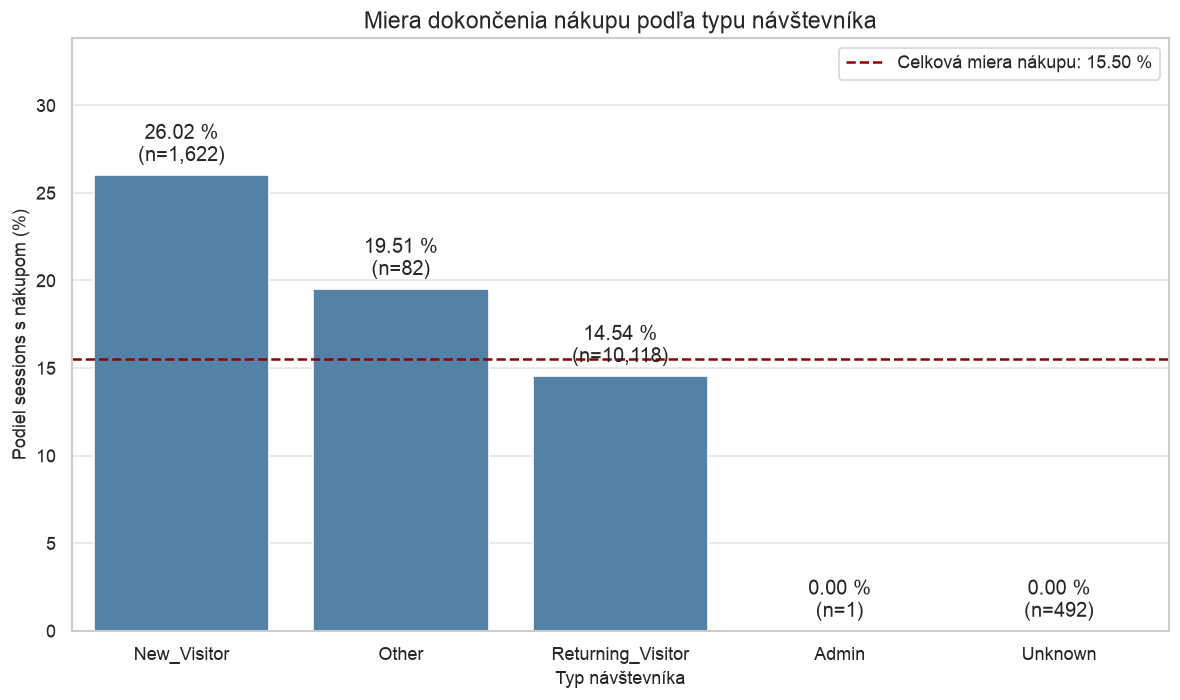

In [3]:
visitor_summary = plot_purchase_rate_by_visitor_type(df_clean)

display(visitor_summary.round(2))

display(
    Image(
        filename=str(
            PROJECT_ROOT
            / "results"
            / "figures"
            / "eda_purchase_rate_by_visitor_type.png"
        )
    )
)

## EDA 2 – Vzťah medzi BounceRates a ExitRates

Cieľom analýzy je zistiť, ako spolu súvisia priemerná miera
okamžitého opustenia stránok (`BounceRates`) a priemerná miera
odchodu zo stránok (`ExitRates`).

Používame očistený dataset. Jeden bod predstavuje jednu session.
Priehľadnosť bodov umožňuje lepšie zobraziť oblasti, v ktorých
sa prekrýva väčší počet pozorovaní.

Vzťah vizualizujeme bodovým grafom a dopĺňame ho Pearsonovým
a Spearmanovým korelačným koeficientom.

Figure saved to: /Users/polo/workspace/suns-zad-1/results/figures/eda_bounce_vs_exit_rates.png


,relationship,sessions,pearson_correlation,spearman_correlation
0,BounceRates vs ExitRates,12315,0.9129,0.6019


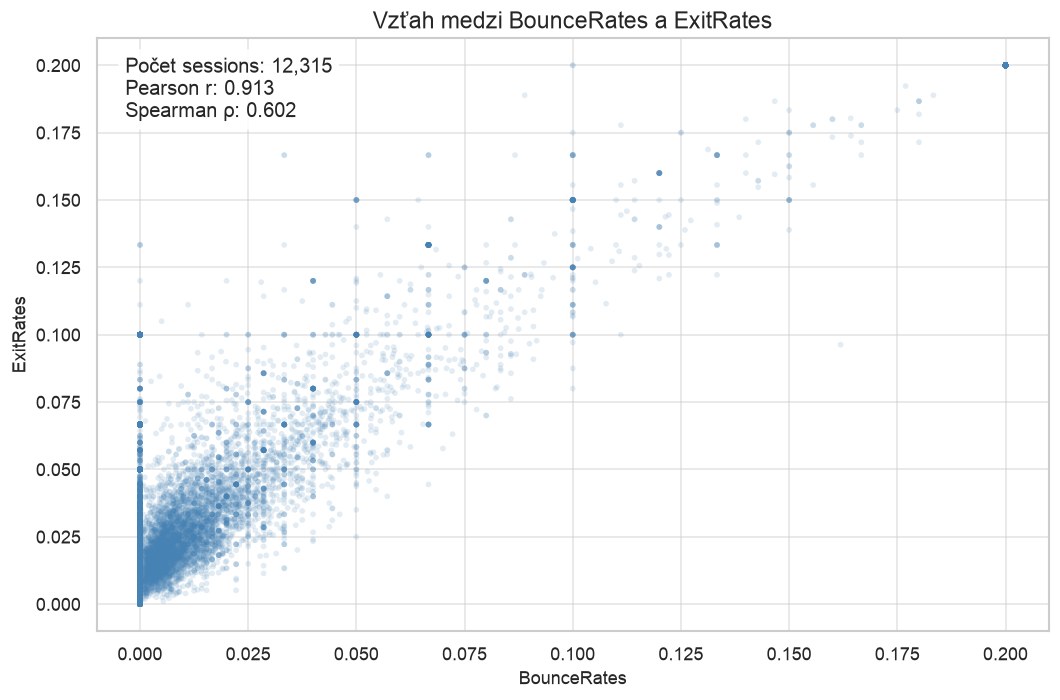

In [4]:
from src.eda import plot_bounce_vs_exit_rates

bounce_exit_summary = plot_bounce_vs_exit_rates(df_clean)

display(bounce_exit_summary.round(4))

display(
    Image(
        filename=str(
            PROJECT_ROOT
            / "results"
            / "figures"
            / "eda_bounce_vs_exit_rates.png"
        )
    )
)

### Vyhodnotenie vzťahu medzi BounceRates a ExitRates

Analýza 12 315 sessions ukázala výraznú pozitívnu súvislosť medzi
premennými `BounceRates` a `ExitRates`. Pearsonov korelačný koeficient
dosiahol hodnotu 0,9129, čo poukazuje na silnú pozitívnu lineárnu
závislosť. Sessions s vyššou priemernou mierou okamžitého opustenia
stránok majú spravidla aj vyššiu priemernú mieru odchodu zo stránok.

Väčšina pozorovaní sa nachádza v ľavej dolnej časti grafu, teda pri
nízkych hodnotách oboch metrík. Zároveň je viditeľná skupina sessions,
pri ktorých je `BounceRates` nulová, ale `ExitRates` dosahuje rôzne
kladné hodnoty. Nulová hodnota jednej metriky preto automaticky
neznamená nulovú hodnotu druhej.

Spearmanov korelačný koeficient dosiahol hodnotu 0,6019. Potvrdzuje
pozitívnu súvislosť aj pri porovnaní poradia hodnôt, avšak táto
súvislosť nie je dokonalá. Rozdiel medzi oboma koeficientmi ukazuje,
že lineárna korelácia a korelácia poradí poskytujú odlišné pohľady
na štruktúru dát.

Premenné teda nesú čiastočne podobnú informáciu, ale nie sú totožné.
Na základe samotnej korelácie nevyvodzujeme príčinný vzťah ani
automaticky neodstraňujeme niektorú z nich zo vstupov modelu.